In [1]:
from scipy.io import loadmat

data = loadmat("../data/Normal_0.mat")

print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'X097_DE_time', 'X097_FE_time', 'X097RPM'])


In [2]:
from scipy.io import loadmat
import numpy as np

data = loadmat("../data/Normal_0.mat")

signal = data["X097_DE_time"].flatten()
rpm = data["X097RPM"].flatten()

print("Signal length:", len(signal))
print("First 10 values:", signal[:10])
print("RPM:", rpm)

Signal length: 243938
First 10 values: [ 0.05319692  0.08866154  0.09971815  0.05862092 -0.00458954 -0.056952
 -0.07176369 -0.05862092 -0.04652123 -0.04985908]
RPM: [1796]


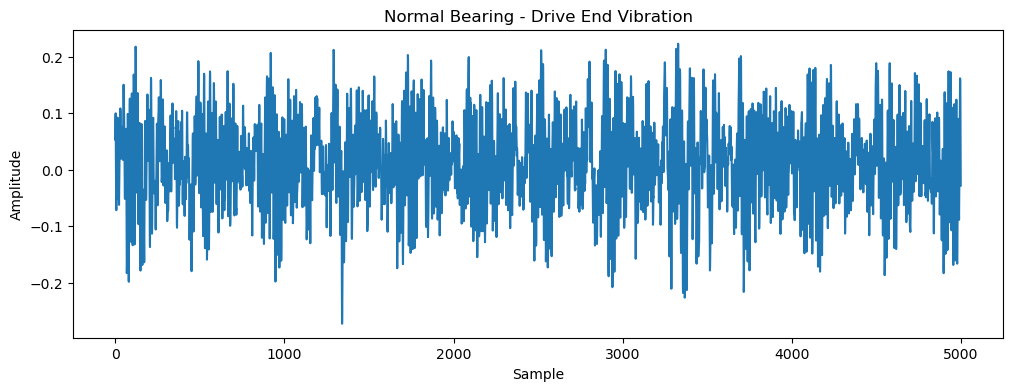

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(signal[:5000])
plt.title("Normal Bearing - Drive End Vibration")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.show()

In [4]:
from scipy.io import loadmat
import numpy as np
import pandas as pd

FILES = {
    "normal": "../data/Normal_0.mat",
    "inner_race": "../data/IR007_0.mat",
    "ball": "../data/B007_0.mat",
    "outer_race": "../data/OR007@6_0.mat"
}

def load_bearing(path):
    data = loadmat(path)

    # Automatically find the Drive End vibration column
    de_key = [k for k in data.keys() if k.endswith("_DE_time")][0]

    signal = data[de_key].flatten()

    # RPM may not exist in every file
    rpm_keys = [k for k in data.keys() if k.endswith("RPM")]
    rpm = data[rpm_keys[0]].flatten()[0] if rpm_keys else None

    return signal, rpm

signals = {}

for label, path in FILES.items():
    signal, rpm = load_bearing(path)
    signals[label] = signal

    print(f"{label:12s} | samples: {len(signal):7d} | RPM: {rpm}")

normal       | samples:  243938 | RPM: 1796
inner_race   | samples:  121265 | RPM: 1797
ball         | samples:  122571 | RPM: 1796
outer_race   | samples:  121991 | RPM: 1796


In [5]:
import numpy as np
import pandas as pd

WINDOW_SIZE = 2048
MAX_SAMPLES = 60000

def extract_features(segment):
    rms = np.sqrt(np.mean(segment ** 2))
    std = np.std(segment)
    kurtosis = (
        np.mean((segment - np.mean(segment)) ** 4)
        / (np.std(segment) ** 4)
    )
    crest = np.max(np.abs(segment)) / rms

    # Frequency-domain features
    fft = np.fft.rfft(segment)
    amplitude = np.abs(fft)
    freqs = np.fft.rfftfreq(len(segment), d=1/12000)

    peak_frequency = freqs[np.argmax(amplitude)]

    return {
        "rms": rms,
        "std": std,
        "kurtosis": kurtosis,
        "crest": crest,
        "peak_frequency": peak_frequency
    }


rows = []

for label, signal in signals.items():

    signal = signal[:MAX_SAMPLES]

    for start in range(0, len(signal) - WINDOW_SIZE, WINDOW_SIZE):

        segment = signal[start:start + WINDOW_SIZE]

        features = extract_features(segment)
        features["label"] = label

        rows.append(features)

features_df = pd.DataFrame(rows)

print("Dataset shape:", features_df.shape)
print()
print(features_df.head())
print()
print(features_df["label"].value_counts())

Dataset shape: (116, 6)

        rms       std  kurtosis     crest  peak_frequency   label
0  0.073256  0.072266  2.954176  3.724845     1037.109375  normal
1  0.079035  0.077993  2.815420  2.869171     1037.109375  normal
2  0.074338  0.073370  2.778240  2.949440     1037.109375  normal
3  0.073688  0.072967  2.930965  3.383105     1037.109375  normal
4  0.072112  0.071265  2.794399  3.115698     1037.109375  normal

label
normal        29
inner_race    29
ball          29
outer_race    29
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

X = features_df.drop(columns=["label"])
y = features_df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    
    "Decision Tree": DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ),
    
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=6,
        random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print("\n" + "=" * 50)
    print(name)
    print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
    print(classification_report(y_test, predictions))


Logistic Regression
Accuracy: 1.0
              precision    recall  f1-score   support

        ball       1.00      1.00      1.00         7
  inner_race       1.00      1.00      1.00         7
      normal       1.00      1.00      1.00         8
  outer_race       1.00      1.00      1.00         7

    accuracy                           1.00        29
   macro avg       1.00      1.00      1.00        29
weighted avg       1.00      1.00      1.00        29


Decision Tree
Accuracy: 1.0
              precision    recall  f1-score   support

        ball       1.00      1.00      1.00         7
  inner_race       1.00      1.00      1.00         7
      normal       1.00      1.00      1.00         8
  outer_race       1.00      1.00      1.00         7

    accuracy                           1.00        29
   macro avg       1.00      1.00      1.00        29
weighted avg       1.00      1.00      1.00        29


Random Forest
Accuracy: 1.0
              precision    recall  f1